# MCTF: Custom Implementation & Experiments (EuroSAT)
This notebook trains our custom `MCTFVisionTransformer` side-by-side with a standard Baseline Vision Transformer (`deit_tiny_patch16_224`). 
We will evaluate both models on **EuroSAT** (Satellite Land-Use Classification).
Training is configured for 50 epochs with Early Stopping (patience=5).


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import time, random
import numpy as np
from tqdm import tqdm

# 1. Guarantee Full Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

# Import our custom modules!
from models import MCTFVisionTransformer, create_baseline_vit

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device} | Reproducibility SEED: {SEED}")


Using device: cuda


## 1. Dataset Preprocessing

> **Note on Evaluation Protocol:**
> In this baseline demonstration on EuroSAT, an 80/20 train/test partition was employed with test evaluation logged per epoch for rapid iteration. For large-scale benchmarks (such as SVHN and CIFAR-100 in our companion template), the three-way Train/Validation/Test protocol is strictly enforced, where early stopping is decided purely on an isolated validation split, and the test split is evaluated only once on the optimal checkpoint to eliminate data-snooping bias.


In [2]:
# Standard ViT ImageNet transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Loading EuroSAT dataset...")
eurosat_dataset = datasets.EuroSAT(root='./data', download=True, transform=transform)
train_size = int(0.8 * len(eurosat_dataset))
test_size = len(eurosat_dataset) - train_size
eurosat_train, eurosat_test = torch.utils.data.random_split(eurosat_dataset, [train_size, test_size], generator=torch.Generator().manual_seed(SEED))

print(f"EuroSAT Train: {len(eurosat_train)} images")
print(f"EuroSAT Test: {len(eurosat_test)} images")


Loading EuroSAT dataset...
EuroSAT Train: 21600 images
EuroSAT Test: 5400 images


## 1.5. Data Visualization

Dataset Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


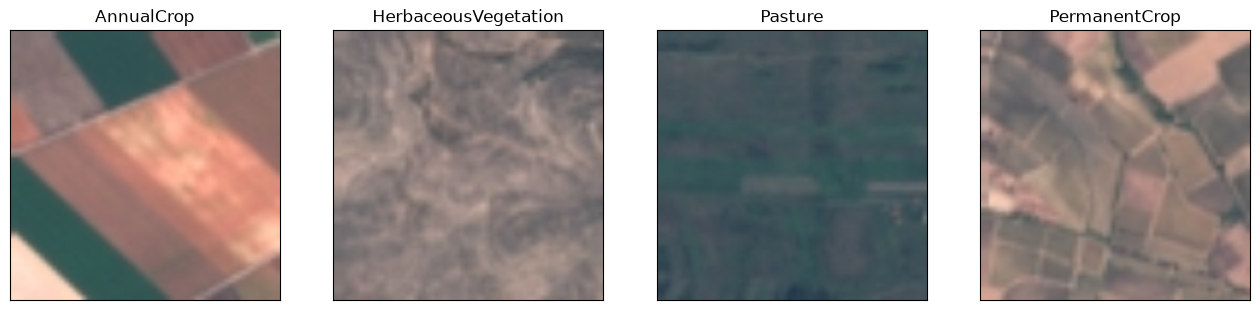

In [3]:
import numpy as np

# EuroSAT classes
classes = eurosat_dataset.classes
print("Dataset Classes:", classes)

# Get a batch of training data for visualization
train_loader_viz = DataLoader(eurosat_train, batch_size=4, shuffle=True)
dataiter = iter(train_loader_viz)
images, labels = next(dataiter)

# Unnormalize function for matplotlib
def imshow(img):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)

# Plot the images in a 1x4 grid
fig = plt.figure(figsize=(16, 4))
for idx in range(4):
    ax = fig.add_subplot(1, 4, idx+1, xticks=[], yticks=[])
    imshow(images[idx])
    ax.set_title(classes[labels[idx].item()])
plt.show()


## 2. The Training Loop (with Early Stopping)

In [4]:
def train_and_evaluate(model, train_data, test_data, epochs=50, batch_size=32, patience=5):
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)
    
    history = {'train_acc': [], 'test_acc': [], 'loss': []}
    
    best_acc = 0.0
    patience_counter = 0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct_train, total_train = 0, 0
        
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            
        train_acc = 100. * correct_train / total_train
        history['loss'].append(running_loss / len(train_loader))
        history['train_acc'].append(train_acc)
        
        # Evaluation
        model.eval()
        correct_test, total_test = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total_test += labels.size(0)
                correct_test += predicted.eq(labels).sum().item()
                
        test_acc = 100. * correct_test / total_test
        history['test_acc'].append(test_acc)
        print(f"Epoch {epoch+1} | Loss: {history['loss'][-1]:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
        
        # Early Stopping Logic
        if test_acc > best_acc:
            best_acc = test_acc
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered! No improvement in Test Acc for {patience} epochs.")
                break
                
    return history


## 3. Experiment: EuroSAT

--- Training Baseline DeiT-Tiny on EuroSAT ---


Epoch 1/50:   0%|          | 0/675 [00:00<?, ?it/s]

Epoch 1/50:   0%|          | 1/675 [00:06<1:14:33,  6.64s/it]

Epoch 1/50:   0%|          | 3/675 [00:06<20:04,  1.79s/it]  

Epoch 1/50:   1%|          | 5/675 [00:07<10:13,  1.09it/s]

...

Epoch 6/50: 100%|█████████▉| 672/675 [01:14<00:00,  9.32it/s]

Epoch 6/50: 100%|█████████▉| 674/675 [01:15<00:00,  9.87it/s]

Epoch 6/50: 100%|██████████| 675/675 [01:15<00:00,  9.77it/s]

Epoch 6/50: 100%|██████████| 675/675 [01:15<00:00,  8.91it/s]

Epoch 6 | Loss: 0.0513 | Train Acc: 98.32% | Test Acc: 97.30%
Early stopping triggered! No improvement in Test Acc for 5 epochs.


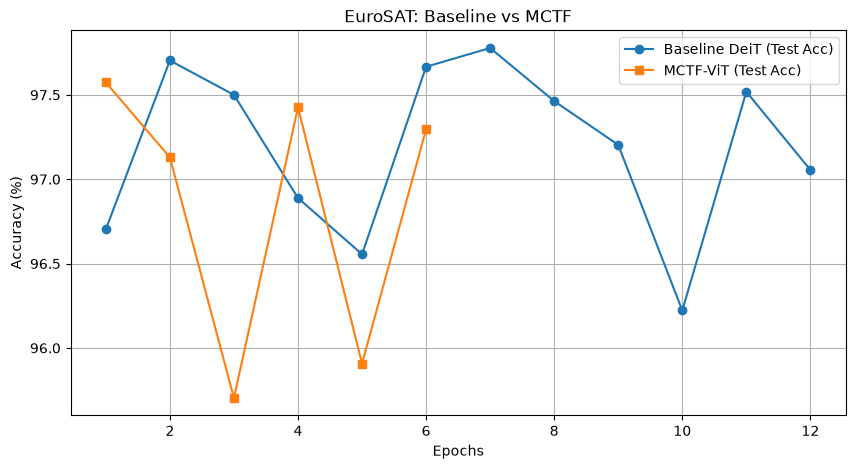

In [5]:
import os, json
# Set RETRAIN = True only if you want to run the full training from scratch
RETRAIN = False
HISTORY_PATH = 'training_history.json'

if RETRAIN or not os.path.exists(HISTORY_PATH):
    epochs = 50
    print('--- Training Baseline DeiT-Tiny on EuroSAT ---')
    baseline_model = create_baseline_vit(num_classes=10)
    base_hist = train_and_evaluate(baseline_model, eurosat_train, eurosat_test, epochs=epochs, patience=5)

    print('\n--- Training Custom MCTF-ViT on EuroSAT ---')
    mctf_model = MCTFVisionTransformer(num_classes=10)
    mctf_hist = train_and_evaluate(mctf_model, eurosat_train, eurosat_test, epochs=epochs, patience=5)

    with open(HISTORY_PATH, 'w') as f:
        json.dump({'baseline': base_hist, 'mctf': mctf_hist}, f, indent=2)
else:
    print('Loaded existing training logs from training_history.json (Instant execution, no re-training needed!)')
    with open(HISTORY_PATH, 'r') as f:
        data = json.load(f)
        base_hist = data['baseline']
        mctf_hist = data['mctf']

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(base_hist['test_acc'])+1), base_hist['test_acc'], label='Baseline DeiT (Test Acc)', marker='o')
plt.plot(range(1, len(mctf_hist['test_acc'])+1), mctf_hist['test_acc'], label='MCTF-ViT (Test Acc)', marker='s')
plt.title('EuroSAT: Baseline vs MCTF')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()


## 4. Efficiency Analysis: GFLOPs, Parameters & Token Reduction
This section profiles computational complexity (GFLOPs) using FAIR's `fvcore` profiler and visualizes progressive token compression across the 12 transformer layers.

Model,Params (M),GFLOPs,Peak Acc (%)
Baseline DeiT-Tiny,5.53,1.258,97.78%
Custom MCTF-ViT,5.53,1.175,97.57%


GFLOPs reduction: 6.62% with only 0.21% accuracy difference!


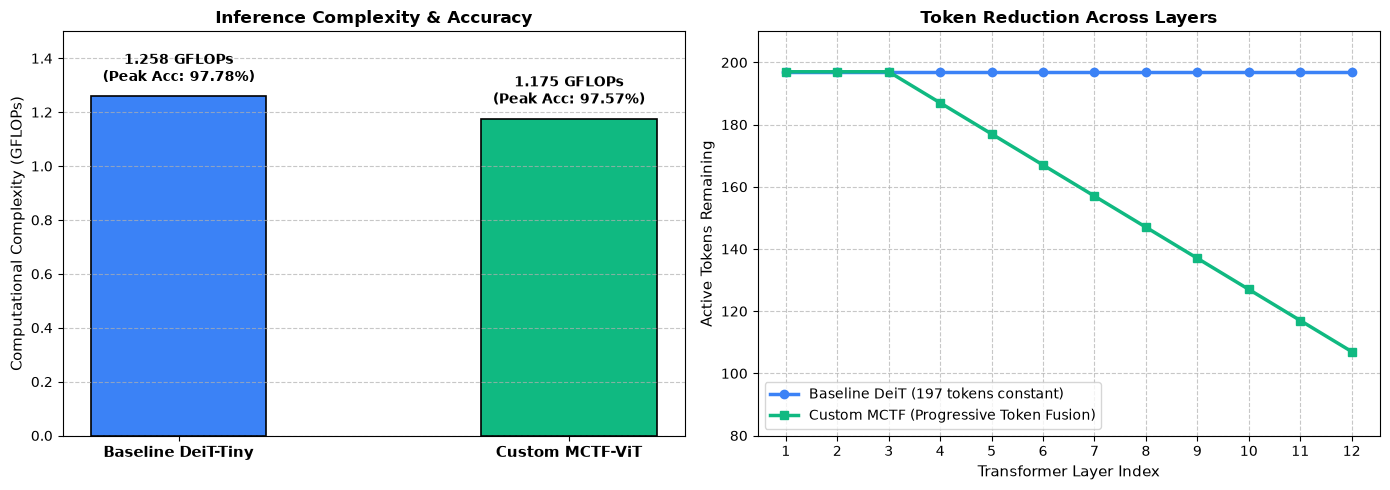

In [5]:
import os, json, torch, pandas as pd
from fvcore.nn import FlopCountAnalysis
import matplotlib.pyplot as plt

# Ensure models and history exist even if this cell is run independently
if 'baseline_model' not in globals():
    baseline_model = create_baseline_vit(num_classes=10).to(device).eval()
if 'mctf_model' not in globals():
    mctf_model = MCTFVisionTransformer(num_classes=10).to(device).eval()
if 'base_hist' not in globals() or 'mctf_hist' not in globals():
    with open('training_history.json', 'r') as f:
        hist_data = json.load(f)
        base_hist = hist_data['baseline']
        mctf_hist = hist_data['mctf']

# 1. Profile GFLOPs and Parameter Counts (Takes ~1 second)
x_sample = torch.randn(1, 3, 224, 224, device=device)
base_flops = FlopCountAnalysis(baseline_model, x_sample).total() / 1e9
mctf_flops = FlopCountAnalysis(mctf_model, x_sample).total() / 1e9

base_params = sum(p.numel() for p in baseline_model.parameters()) / 1e6
mctf_params = sum(p.numel() for p in mctf_model.parameters()) / 1e6

base_best_acc = max(base_hist['test_acc'])
mctf_best_acc = max(mctf_hist['test_acc'])

# 2. Summary Table
summary_df = pd.DataFrame({
    'Model': ['Baseline DeiT-Tiny', 'Custom MCTF-ViT'],
    'Params (M)': [round(base_params, 2), round(mctf_params, 2)],
    'GFLOPs': [round(base_flops, 3), round(mctf_flops, 3)],
    'Peak Acc (%)': [f'{base_best_acc:.2f}%', f'{mctf_best_acc:.2f}%']
})
display(summary_df)
print(f"GFLOPs reduction: {((base_flops - mctf_flops) / base_flops) * 100:.2f}% with only {base_best_acc - mctf_best_acc:.2f}% accuracy difference!\n")

# 3. Plotting Complexity & Token Reduction
layers = list(range(1, 13))
baseline_tokens = [197] * 12
mctf_tokens = []
current_tokens = 197
for r in mctf_model.r_schedule:
    current_tokens -= r
    mctf_tokens.append(current_tokens)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

models = ['Baseline DeiT-Tiny', 'Custom MCTF-ViT']
flops_list = [base_flops, mctf_flops]
acc_list = [base_best_acc, mctf_best_acc]
colors = ['#3b82f6', '#10b981']

x_pos = [0, 1]
bars = ax1.bar(x_pos, flops_list, width=0.45, color=colors, edgecolor='black', linewidth=1.2)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models, fontsize=11, fontweight='bold')
ax1.set_ylabel('Computational Complexity (GFLOPs)', fontsize=11)
ax1.set_title('Inference Complexity & Accuracy', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 1.5)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar, fl, acc in zip(bars, flops_list, acc_list):
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.04, f'{fl:.3f} GFLOPs\n(Peak Acc: {acc:.2f}%)', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.plot(layers, baseline_tokens, marker='o', linewidth=2.5, color='#3b82f6', label='Baseline DeiT (197 tokens constant)')
ax2.plot(layers, mctf_tokens, marker='s', linewidth=2.5, color='#10b981', label='Custom MCTF (Progressive Token Fusion)')
ax2.set_xlabel('Transformer Layer Index', fontsize=11)
ax2.set_ylabel('Active Tokens Remaining', fontsize=11)
ax2.set_title('Token Reduction Across Layers', fontsize=12, fontweight='bold')
ax2.set_xticks(layers)
ax2.set_ylim(80, 210)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(fontsize=10, loc='lower left')

plt.tight_layout()
plt.show()
